# Modèle Decision Tree (Arbre de Décision)

Ce notebook contient l'implémentation et l'évaluation du modèle Decision Tree pour prédire l'attrition des employés.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 40)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle Decision Tree

Le Decision Tree (arbre de décision) est un modèle de classification supervisée qui divise les données en fonction de critères de plus en plus précis à chaque nœud, créant ainsi une structure en arbre. L'avantage des arbres de décision réside dans leur simplicité d'interprétation.

In [4]:
# Initialisation et entraînement du modèle
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


## 5. Prédictions

In [5]:
# Prédictions sur l'ensemble de test
y_pred = tree_model.predict(X_test)
y_proba = tree_model.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### 6.1 Matrice de confusion

Matrice de Confusion (Decision Tree) :
 [[1095   20]
 [  32  176]]


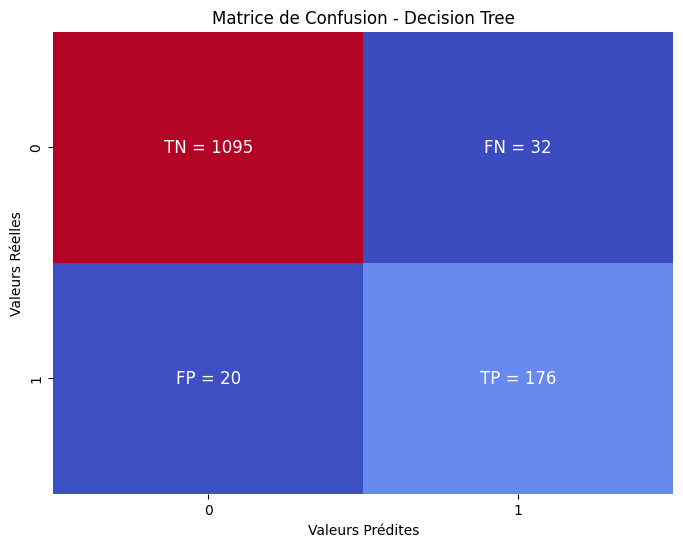

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (Decision Tree) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - Decision Tree")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (Decision Tree) :\n", class_report)

Rapport de Classification (Decision Tree) :
               precision    recall  f1-score   support

           0       0.97      0.98      0.98      1115
           1       0.90      0.85      0.87       208

    accuracy                           0.96      1323
   macro avg       0.93      0.91      0.92      1323
weighted avg       0.96      0.96      0.96      1323



### 6.3 Score AUC-ROC

In [8]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC (Decision Tree) : {roc_auc:.4f}")

AUC-ROC (Decision Tree) : 0.9141


### 6.4 Courbe ROC

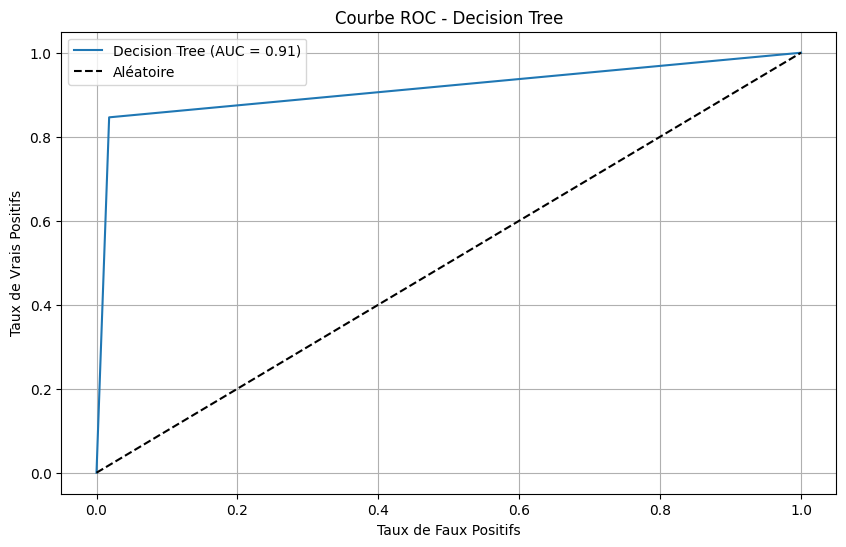

In [9]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - Decision Tree")
plt.legend()
plt.grid(True)
plt.show()

## 7. Importance des features

Top 10 features les plus importantes:
                     feature  importance
0   avg_working_time_seconds    0.176882
14         TotalWorkingYears    0.096751
6                        Age    0.095154
10             MonthlyIncome    0.091245
17   YearsSinceLastPromotion    0.045923
18      YearsWithCurrManager    0.044560
5            WorkLifeBalance    0.042194
16            YearsAtCompany    0.038687
7           DistanceFromHome    0.036799
11        NumCompaniesWorked    0.036350


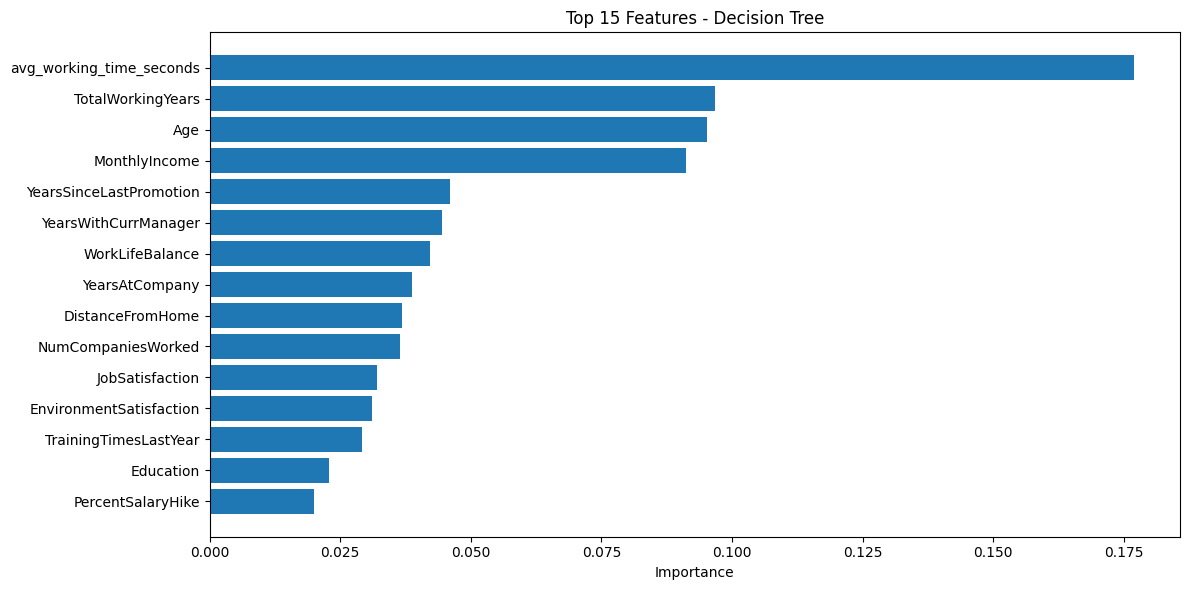

In [10]:
# Affichage de l'importance des features
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': tree_model.feature_importances_
}).sort_values('importance', ascending=False)

print("Top 10 features les plus importantes:")
print(feature_importance.head(10))

# Visualisation
plt.figure(figsize=(12, 6))
plt.barh(feature_importance.head(15)['feature'], feature_importance.head(15)['importance'])
plt.xlabel('Importance')
plt.title('Top 15 Features - Decision Tree')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Sauvegarde du modèle et des résultats

In [11]:
# Sauvegarde du modèle
with open('Data/decision_tree_model.pkl', 'wb') as f:
    pickle.dump(tree_model, f)

# Sauvegarde des résultats
results = {
    'model_name': 'Decision Tree',
    'predictions': y_pred,
    'probabilities': y_proba,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix,
    'feature_importance': feature_importance
}

with open('Data/decision_tree_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


## Résumé

Ce notebook a permis de :
1. Charger les données préparées
2. Entraîner un modèle Decision Tree
3. Évaluer ses performances avec plusieurs métriques
4. Analyser l'importance des features
5. Sauvegarder le modèle et les résultats pour comparaison ultérieure